# Diabetes Challenge

Your task today is to **analyze** the Kaggle "Pima Indians Diabetes Database" and to **predict** whether a patient has Diabetes or not.

## Task:
- Load the data from the database. The schema is called `diabetes`. To connect to the database you need to copy the `.env` file from the visualization or hands-on-ml repository into this repo. Explore the database, try to establish what the relationships between the tables are (1-1, 1-N, N-M). Explain to yourself and the group what data do you see and whether it makes sense. What JOINs are appropriate to use and why? 
- Use at least two different classification algorithms we have learned so far to predict Diabetes patients. 
- Discuss before you start with the modeling process which **evaluation metric** you choose and explain why.
- Implement a GridSearchCV or RandomizedSearchCV to tune the hyperparameters of your model.
- **Optional:** If you have time at the end, try to use sklearn's pipline module to encapsulate all the steps into a pipeline.

Don't forget to split your data in train and test set. And analyze your final model on the test data. It might also be necessary to scale your data in order to improve the performance of some of the models.


## Helpful links and advise:
- [sklearn documentation on hyperparameter tuning](https://scikit-learn.org/stable/modules/grid_search.html#grid-search)
- It might be helpful to check some sources on how to deal with imbalanced data. 
    * [8 Tactics to Combat Imbalanced Classes](https://machinelearningmastery.com/tactics-to-combat-imbalanced-classes-in-your-machine-learning-dataset/)
    * [Random-Oversampling/Undersampling](https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/)


# Data Description

## Context
This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

## Acknowledgements
Smith, J.W., Everhart, J.E., Dickson, W.C., Knowler, W.C., & Johannes, R.S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. In Proceedings of the Symposium on Computer Applications and Medical Care (pp. 261--265). IEEE Computer Society Press.

## About this dataset
The datasets consist of several medical predictor (independent) variables and one target (dependent) variable, Outcome. Independent variables include the number of pregnancies the patient has had, their BMI, insulin level, age, and so on. For the outcome class value 1 is interpreted as "tested positive for diabetes".

|Column Name| Description|
|:------------|:------------|
|Pregnancies|Number of times pregnant|
|Glucose|Plasma glucose concentration a 2 hours in an oral glucose tolerance test|
|BloodPressure|Diastolic blood pressure (mm Hg)|
|SkinThickness|Triceps skin fold thickness (mm)|
|Insulin|2-Hour serum insulin (mu U/ml)|
|BMI|Body mass index (weight in kg/(height in m)^2)|
|DiabetesPedigreeFunction| Diabetes pedigree function|
|Age| Age (years)|
|Outcome|Class variable (0 or 1) |

# 1. The data

The CSV is the result of joining four database tables (we can tell from the duplicated `id` / `patientid` columns):

| Table (content) | Key | Relationship to patient |
|:--|:--|:--|
| Patient (`id.3`) | `id` | - |
| Blood measurements (glucose, blood pressure, insulin, date) | `patientid` | **1-N**: one patient, several measurements |
| Body data (age, pregnancies, BMI, skin thickness) | `patientid` | **1-1** |
| Diagnosis (pedigree function, outcome) | `patientid` | **1-1** |

The measurements were **LEFT JOINed** to the other tables, so 235 measurements without a patient record ended up with empty values.
For training we only need patients with a known outcome, so an **INNER JOIN** would have been enough.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import fbeta_score, recall_score, precision_score, confusion_matrix, make_scorer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv("data/blood_data.csv")
print(df.shape)
df.head()

(1771, 17)


,insulin,glucose,bloodpressure,patientid,id,measurement_date,id.1,Age,pregnancies,bmi,skinthickness,patientid.1,id.2,diabetespedigreefunction,outcome,patientid.2,id.3
0,80,172,117,1,769,2022-12-01,1.0,50.0,6.0,33.6,35.0,1.0,1.0,0.627,1.0,1.0,1.0
1,0,148,72,1,1,2022-12-13,1.0,50.0,6.0,33.6,35.0,1.0,1.0,0.627,1.0,1.0,1.0
2,80,54,93,2,770,2022-12-01,2.0,31.0,1.0,26.6,29.0,2.0,2.0,0.351,0.0,2.0,2.0
3,0,85,66,2,2,2022-12-13,2.0,31.0,1.0,26.6,29.0,2.0,2.0,0.351,0.0,2.0,2.0
4,1,168,100,3,771,2022-12-01,3.0,32.0,8.0,23.3,0.0,3.0,3.0,0.672,1.0,3.0,3.0


Every patient was measured on **two dates**. Which one should we use?
We check how strongly glucose (the most important feature) is related to the outcome on each date:

In [3]:
labeled = df.dropna(subset=["outcome"])  # only rows with a known diagnosis

for date, group in labeled.groupby("measurement_date"):
    print(date, "correlation glucose/outcome:", round(group["glucose"].corr(group["outcome"]), 3))

2022-12-01 correlation glucose/outcome: -0.057
2022-12-13 correlation glucose/outcome: 0.467


On 2022-12-01 glucose has **no relationship** with the outcome (≈ 0) - these values look like noise.
On 2022-12-13 the correlation is clear (≈ 0.47). So we **keep only 2022-12-13** (one row per patient).
Averaging both dates would mix good data with noise.

In [4]:
data = labeled[labeled["measurement_date"] == "2022-12-13"]

# IDs and the date don't help to predict anything
data = data.drop(columns=["patientid", "id", "measurement_date", "id.1", "patientid.1", "id.2", "patientid.2", "id.3"])
print(data.shape)
data.head()

(768, 9)


,insulin,glucose,bloodpressure,Age,pregnancies,bmi,skinthickness,diabetespedigreefunction,outcome
1,0,148,72,50.0,6.0,33.6,35.0,0.627,1.0
3,0,85,66,31.0,1.0,26.6,29.0,0.351,0.0
5,0,183,64,32.0,8.0,23.3,0.0,0.672,1.0
7,94,89,66,21.0,1.0,28.1,23.0,0.167,0.0
9,168,137,40,33.0,0.0,43.1,35.0,2.288,1.0


# 2. Which metric?

The model can make two kinds of mistakes:
- **False negative**: a sick patient is told she is healthy → she gets no treatment. **Very bad.**
- **False positive**: a healthy patient gets a false alarm → one more test. Annoying, but not dangerous.

So we care most about **recall** (how many sick patients do we find?).
Only optimizing recall is too easy (just call everyone sick), so we use the **F2 score**:
it combines recall and precision, but counts recall **twice as much**.

In [5]:
X = data.drop(columns="outcome")
y = data["outcome"].astype(int)

# 2/3 train, 1/3 test. stratify=y keeps the same share of sick patients in both parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42, stratify=y)
print(y_train.value_counts(normalize=True))  # ~35% sick -> imbalanced

outcome
0    0.651751
1    0.348249
Name: proportion, dtype: float64


# 3. Cleaning

Some columns contain **0**, which is impossible for a living person (e.g. blood pressure 0).
These zeros are really **missing values**. How many are there?

In [6]:
(X_train == 0).mean().round(2)  # share of zeros per column (0 pregnancies is fine!)

insulin                     0.48
glucose                     0.01
bloodpressure               0.04
Age                         0.00
pregnancies                 0.14
bmi                         0.02
skinthickness               0.29
diabetespedigreefunction    0.00
dtype: float64

- **Insulin**: about half the values are missing → we drop the column.
- **Glucose, blood pressure, BMI, skin thickness**: we replace the zeros with the median.
  This happens **inside the pipeline** (section 5), so the median is always calculated only on training data.

In [7]:
X_train = X_train.drop(columns="insulin")
X_test = X_test.drop(columns="insulin")

zero_cols = ["glucose", "bloodpressure", "bmi", "skinthickness"]  # here 0 means "missing"

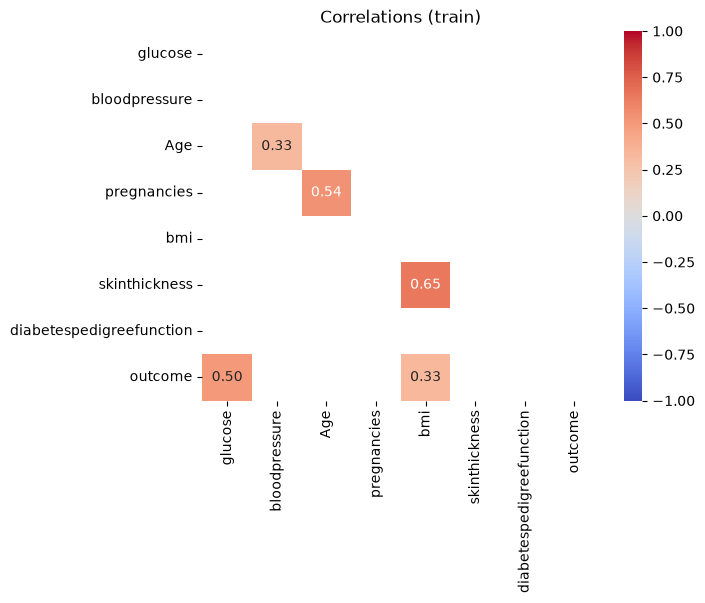

In [8]:
# Correlations on the training data (zeros treated as missing)
train = X_train.copy()
train[zero_cols] = train[zero_cols].replace(0, np.nan)
train["outcome"] = y_train
corr = train.corr()

# Show only the lower half and only correlations with |r| >= 0.3
mask = np.triu(np.ones_like(corr, dtype=bool)) | (corr.abs() < 0.3)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlations (train)")
plt.show()

# 4. Baseline

Before any machine learning: a simple rule. **"Glucose above 130 → diabetes."**
Every model has to beat this, otherwise it is not worth it.

In [9]:
y_pred_base = (X_test["glucose"] > 130).astype(int)
baseline_f2 = fbeta_score(y_test, y_pred_base, beta=2)

print("F2:       ", round(baseline_f2, 3))
print("Recall:   ", round(recall_score(y_test, y_pred_base), 3))
print("Precision:", round(precision_score(y_test, y_pred_base), 3))

F2:        0.586
Recall:    0.584
Precision: 0.591


# 5. Models

Every model runs in the same **pipeline** (a fixed sequence of steps):
1. **Imputer**: replace the zeros in `zero_cols` with the median
2. **Scaler**: bring all features to the same scale (important for KNN and Logistic Regression)
3. **SMOTE**: create extra artificial sick patients, so the model sees both classes equally often (only during training)
4. **Model**

We test three models and tune their settings (**hyperparameters**) with `GridSearchCV`:
it tries every combination with 5-fold cross-validation and keeps the one with the best F2.

In [10]:
def make_pipe(model):
    imputer = ColumnTransformer(
        [("zeros", SimpleImputer(missing_values=0, strategy="median"), zero_cols)],
        remainder="passthrough",  # all other columns stay unchanged
    )
    return Pipeline([
        ("imputer", imputer),
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model),
    ])

f2 = make_scorer(fbeta_score, beta=2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # 5 folds, same share of sick patients in each

# model + the settings we want to try ("model__" = setting of the pipeline step "model")
grids = {
    "LogReg": (LogisticRegression(max_iter=1000), {"model__C": [0.01, 0.1, 1, 10]}),
    "Tree":   (DecisionTreeClassifier(random_state=42), {"model__max_depth": [2, 3, 4, 5, 7, 10],
                                                          "model__min_samples_leaf": [1, 5, 10, 20]}),
    "KNN":    (KNeighborsClassifier(), {"model__n_neighbors": list(range(3, 40, 2)), "model__p": [1, 2]}),
}

best = {}  # best tuned pipeline per model
for name, (model, grid) in grids.items():
    search = GridSearchCV(make_pipe(model), grid, scoring=f2, cv=cv, n_jobs=-1).fit(X_train, y_train)
    best[name] = search.best_estimator_
    print(f"{name:7s} CV F2: {search.best_score_:.3f}  {search.best_params_}")

LogReg  CV F2: 0.695  {'model__C': 1}


Tree    CV F2: 0.696  {'model__max_depth': 7, 'model__min_samples_leaf': 20}


KNN     CV F2: 0.769  {'model__n_neighbors': 21, 'model__p': 2}


# 6. Threshold tuning

A model doesn't really say "sick" or "healthy" - it gives a **probability**.
By default everything above **0.5** counts as "sick".
If we lower this threshold, we find more sick patients (higher recall) but get more false alarms (lower precision).

We search for the threshold with the best F2 - **only on training data** (cross-validation), so the test set stays untouched.

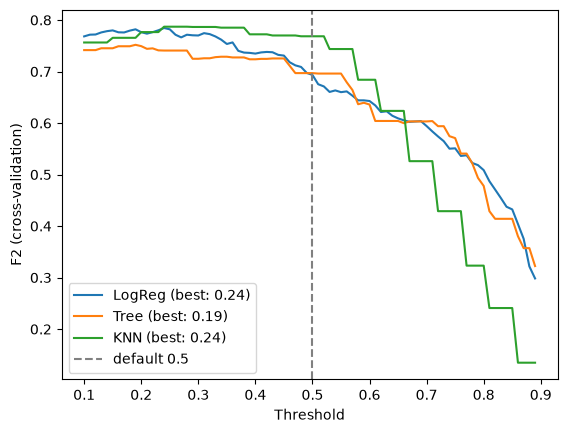

Final model: KNN with threshold 0.24


In [11]:
thresholds = np.arange(0.10, 0.90, 0.01)
f2_curves, best_thresholds = {}, {}

for name, pipe in best.items():
    # probability for every training row, predicted by a model that did NOT see this row
    proba = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    f2_curves[name] = [fbeta_score(y_train, proba >= t, beta=2) for t in thresholds]
    best_thresholds[name] = thresholds[np.argmax(f2_curves[name])]
    plt.plot(thresholds, f2_curves[name], label=f"{name} (best: {best_thresholds[name]:.2f})")

plt.axvline(0.5, color="grey", linestyle="--", label="default 0.5")
plt.xlabel("Threshold")
plt.ylabel("F2 (cross-validation)")
plt.legend()
plt.show()

# Final model = best F2 in cross-validation (we never choose by the test score!)
final_name = max(f2_curves, key=lambda name: max(f2_curves[name]))
print("Final model:", final_name, "with threshold", round(best_thresholds[final_name], 2))

# 7. Results on the test set

Now - and only now - we use the test set. Each model at three stages:
**Default** (no tuning) → **GridSearch** (tuned settings) → **+ Threshold** (tuned settings and threshold).

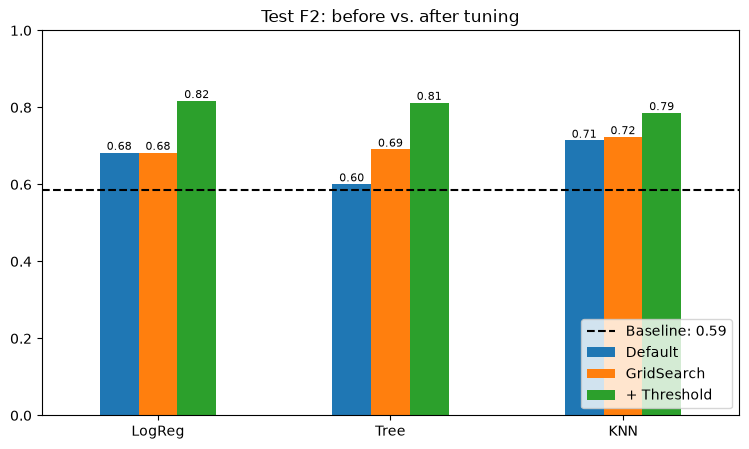

In [12]:
results = {}
for name, (model, grid) in grids.items():
    default = make_pipe(model).fit(X_train, y_train)
    proba = best[name].predict_proba(X_test)[:, 1]
    results[name] = {
        "Default":     fbeta_score(y_test, default.predict(X_test), beta=2),
        "GridSearch":  fbeta_score(y_test, best[name].predict(X_test), beta=2),
        "+ Threshold": fbeta_score(y_test, proba >= best_thresholds[name], beta=2),
    }
results = pd.DataFrame(results).T  # rows = models, columns = stages

ax = results.plot(kind="bar", rot=0, ylim=(0, 1), figsize=(9, 5), title="Test F2: before vs. after tuning")
ax.axhline(baseline_f2, color="black", linestyle="--", label=f"Baseline: {baseline_f2:.2f}")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.legend(loc="lower right")
plt.show()

In [13]:
# The final model in detail: threshold 0.5 vs. tuned threshold
proba = best[final_name].predict_proba(X_test)[:, 1]

for t in [0.5, best_thresholds[final_name]]:
    pred = proba >= t
    print(f"Threshold {t:.2f}:  F2 {fbeta_score(y_test, pred, beta=2):.3f}  "
          f"Recall {recall_score(y_test, pred):.3f}  Precision {precision_score(y_test, pred):.3f}")
    print(confusion_matrix(y_test, pred), "\n")  # rows: actual healthy/sick, columns: predicted healthy/sick

Threshold 0.50:  F2 0.724  Recall 0.753  Precision 0.626
[[125  40]
 [ 22  67]] 

Threshold 0.24:  F2 0.786  Recall 0.933  Precision 0.483
[[76 89]
 [ 6 83]] 



# 8. Conclusion

- **All models clearly beat the baseline** (glucose > 130, F2 ≈ 0.59).
- **GridSearch helps a little**; the big jump comes from **lowering the threshold** (F2 +0.06 to +0.13).
- **Final model: KNN** (k = 21) with threshold 0.24 - chosen by cross-validation, not by the test set.
- On the test set it finds **83 of 89 sick patients** (recall 0.93), but raises **89 false alarms** (precision 0.48).
  For a screening test that is acceptable: a false alarm only means one more test, a missed patient means no treatment.
- Logistic Regression is practically as good (CV F2 0.784 vs. 0.787) and easier to explain - a valid alternative.